In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "month":[
        "2025-01", "2025-02", "2025-03", "2025-04", "2025-05", "2025-06", "2025-07",
        "2025-08", "2025-09", "2025-10", "2025-11", "2025-12"
    ],
    "production": [
        53607462, 46542078, 49436481, 50231801, 51096093, 50635351,
        52783823, 50276843, 46733181, 49192821, 47661413, 46841541
    ]
}

df = pd.DataFrame(data)

df["month"] = pd.to_datetime(df["month"])

df

,month,production
0,2025-01-01,53607462
1,2025-02-01,46542078
2,2025-03-01,49436481
3,2025-04-01,50231801
4,2025-05-01,51096093
5,2025-06-01,50635351
6,2025-07-01,52783823
7,2025-08-01,50276843
8,2025-09-01,46733181
9,2025-10-01,49192821


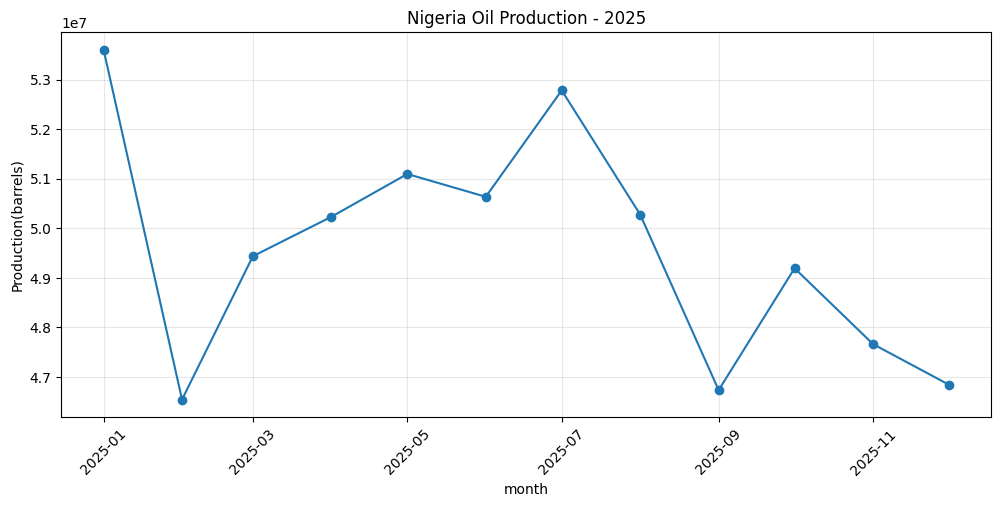

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    df["month"],
    df["production"],
    marker= "o"
)

plt.title("Nigeria Oil Production - 2025")
plt.xlabel("month")
plt.ylabel("Production(barrels)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# building baseline forecast

from statsmodels.tsa.holtwinters import ExponentialSmoothing

# set month as the index

ts = df.set_index("month") ["production"]

# build the forecasting model

model = ExponentialSmoothing(
    ts,
    trend="add",
    seasonal=None
)

fit = model.fit()

# forecast the next 3 months

forecast = fit.forecast(3)

forecast

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,0
2026-01-01,4.799728e+07
2026-02-01,4.775466e+07
2026-03-01,4.751203e+07


In [ ]:
# putting actual and forecast together

forecast_df= forecast.reset_index()

forecast_df.columns = ["month", "forecast_production"]

forecast_df

,month,forecast_production
0,2026-01-01,4.799728e+07
1,2026-02-01,4.775466e+07
2,2026-03-01,4.751203e+07


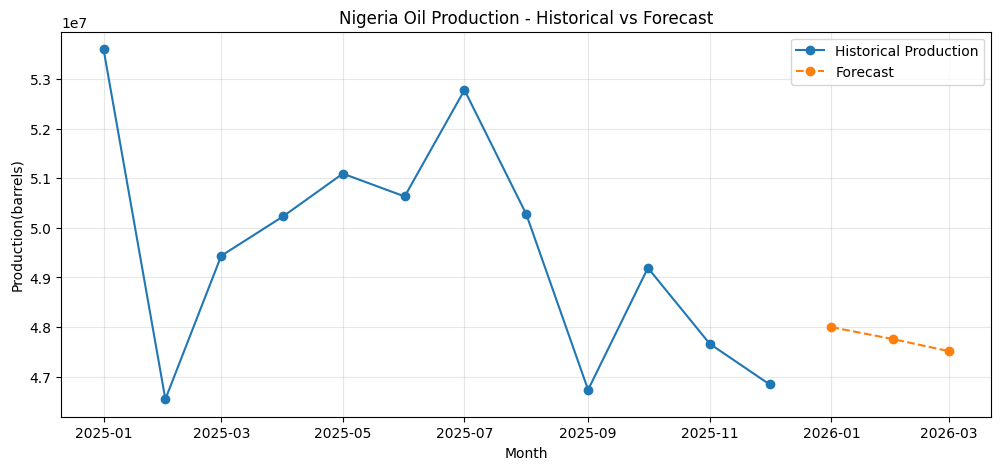

In [ ]:
# visualization

plt.figure(figsize=(12, 5))

plt.plot(
    ts.index,
    ts.values,
    marker="o",
    label="Historical Production"
)

plt.plot(
    forecast.index,
    forecast.values,
    marker="o",
    linestyle="--",
    label="Forecast"
)

plt.title("Nigeria Oil Production - Historical vs Forecast")
plt.xlabel("Month")
plt.ylabel("Production(barrels)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# testing the reasonable accurate

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# use first 9 months for trainning

train = ts.iloc[:9]

# keep last 3 months as actual values for testing

test = ts.iloc[9:]

#  build same forecasting model

validation_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal=None
)

validation_fit = validation_model.fit()

# forecast the 3 months already known

validation_forecast = validation_fit.forecast(len(test))

# calculate errors

mae = mean_absolute_error(test, validation_forecast)
rmse = np.sqrt(mean_squared_error(test, validation_forecast))

print("MAE:", mae)
print("RMSE:", rmse)


MAE: 6078926.438073347
RMSE: 6236482.155493337


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/holtwinters/model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


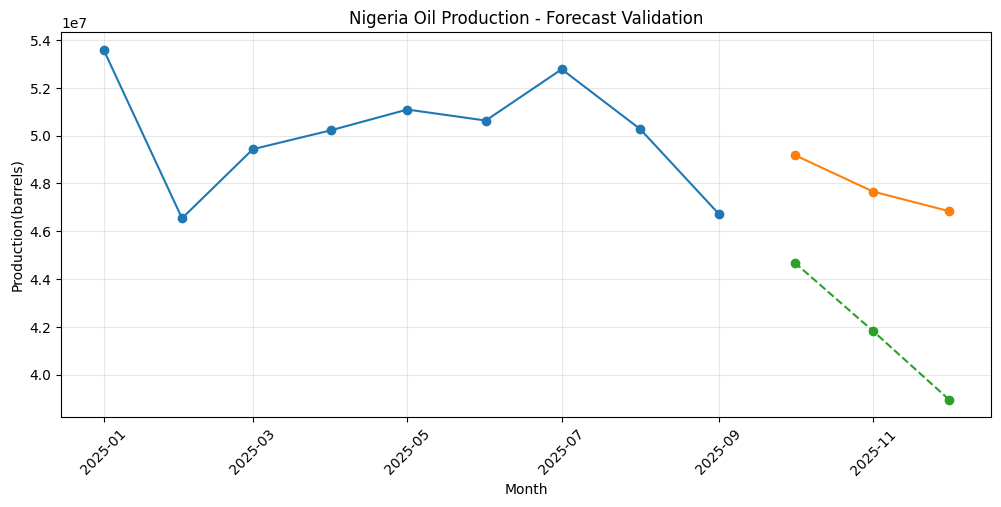

In [ ]:
# evaluation visualization

plt.figure(figsize= (12, 5))

plt.plot(train.index, train.values, marker="o", label="Training Data")
plt.plot(test.index, test.values, marker="o", label="Actual")
plt.plot(
    validation_forecast.index,
    validation_forecast.values,
    marker="o",
    linestyle="--",
    label="Validation Forecast"
)

plt.title("Nigeria Oil Production - Forecast Validation")
plt.xlabel("Month")
plt.ylabel("Production(barrels)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.show()

In [ ]:
# fit an ARIMA baseine

from statsmodels.tsa.arima.model import ARIMA

# train on jan-sep 2025

arima_model = ARIMA(train, order = (1, 1, 1))

arima_fit = arima_model.fit()

# forecast oct-dec 2025

arima_forecast = arima_fit.forecast(steps=3)

arima_forecast

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,predicted_mean
2025-10-01,4.711594e+07
2025-11-01,4.699565e+07
2025-12-01,4.703346e+07


In [ ]:
# calculate its errors

arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))

print("ARIMA MAE:", arima_mae)
print("ARIMA RMSE:", arima_rmse)

ARIMA MAE: 978184.8064404229
ARIMA RMSE: 1264052.5687183999


In [ ]:
# train ARIMA using all 12 months of 2025

final_arima_model = ARIMA(
    ts,
    order=(1, 1, 1)
)

final_arima_fit = final_arima_model.fit()

# forecast the next 3 months

final_forecast = final_arima_fit.forecast(steps= 3)

final_forecast

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,predicted_mean
2026-01-01,4.690526e+07
2026-02-01,4.688639e+07
2026-03-01,4.689198e+07


In [ ]:
# month historical/forecast production

forecast_df = final_forecast.reset_index()

forecast_df.columns = ["month", "forecast_production"]

forecast_df

,month,forecast_production
0,2026-01-01,4.690526e+07
1,2026-02-01,4.688639e+07
2,2026-03-01,4.689198e+07


In [ ]:
forecast_df["type"] = "Forecast"
forecast_df

,month,forecast_production,type
0,2026-01-01,4.690526e+07,Forecast
1,2026-02-01,4.688639e+07,Forecast
2,2026-03-01,4.689198e+07,Forecast


In [ ]:
forecast_powerbi = forecast_df.rename(
    columns={"forecast_production": "production"}
)

forecast_powerbi = forecast_powerbi[["month", "production", "type"]]

forecast_powerbi

,month,production,type
0,2026-01-01,4.690526e+07,Forecast
1,2026-02-01,4.688639e+07,Forecast
2,2026-03-01,4.689198e+07,Forecast


In [ ]:
historical_powerbi = df[["month", "production"]].copy()
historical_powerbi["type"] = "Historical"

combined = pd.concat([historical_powerbi, forecast_powerbi], ignore_index=True)

combined

,month,production,type
0,2025-01-01,5.360746e+07,Historical
1,2025-02-01,4.654208e+07,Historical
2,2025-03-01,4.943648e+07,Historical
3,2025-04-01,5.023180e+07,Historical
4,2025-05-01,5.109609e+07,Historical
5,2025-06-01,5.063535e+07,Historical
6,2025-07-01,5.278382e+07,Historical
7,2025-08-01,5.027684e+07,Historical
8,2025-09-01,4.673318e+07,Historical
9,2025-10-01,4.919282e+07,Historical


In [ ]:
# exprt code

combined.to_csv(
    "Nigeria_Oil_Production_Historical_Forecast.csv", index=False
)

In [ ]:
from google.colab import files

files.download("Nigeria_Oil_Production_Historical_Forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>